In [2]:
!nvidia-smi

Fri Nov 13 11:36:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Скачиваем cat...
Скачиваем dog...
candidate_label
cat    50
dog    50


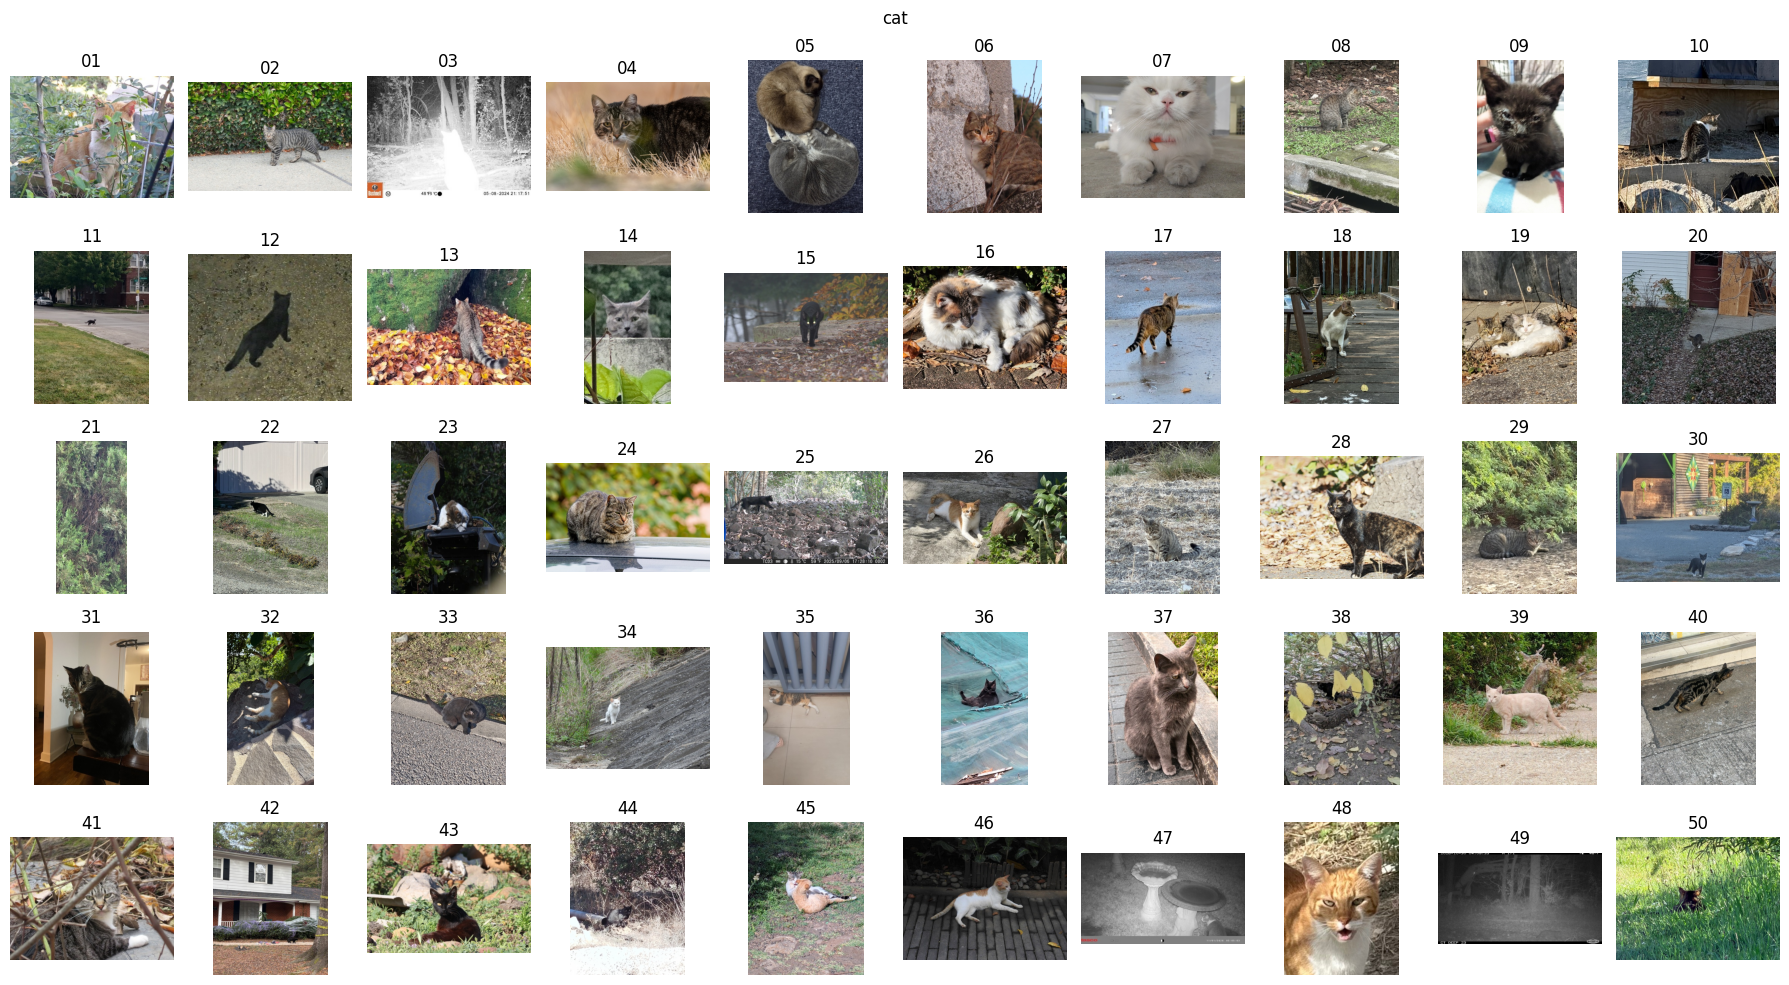

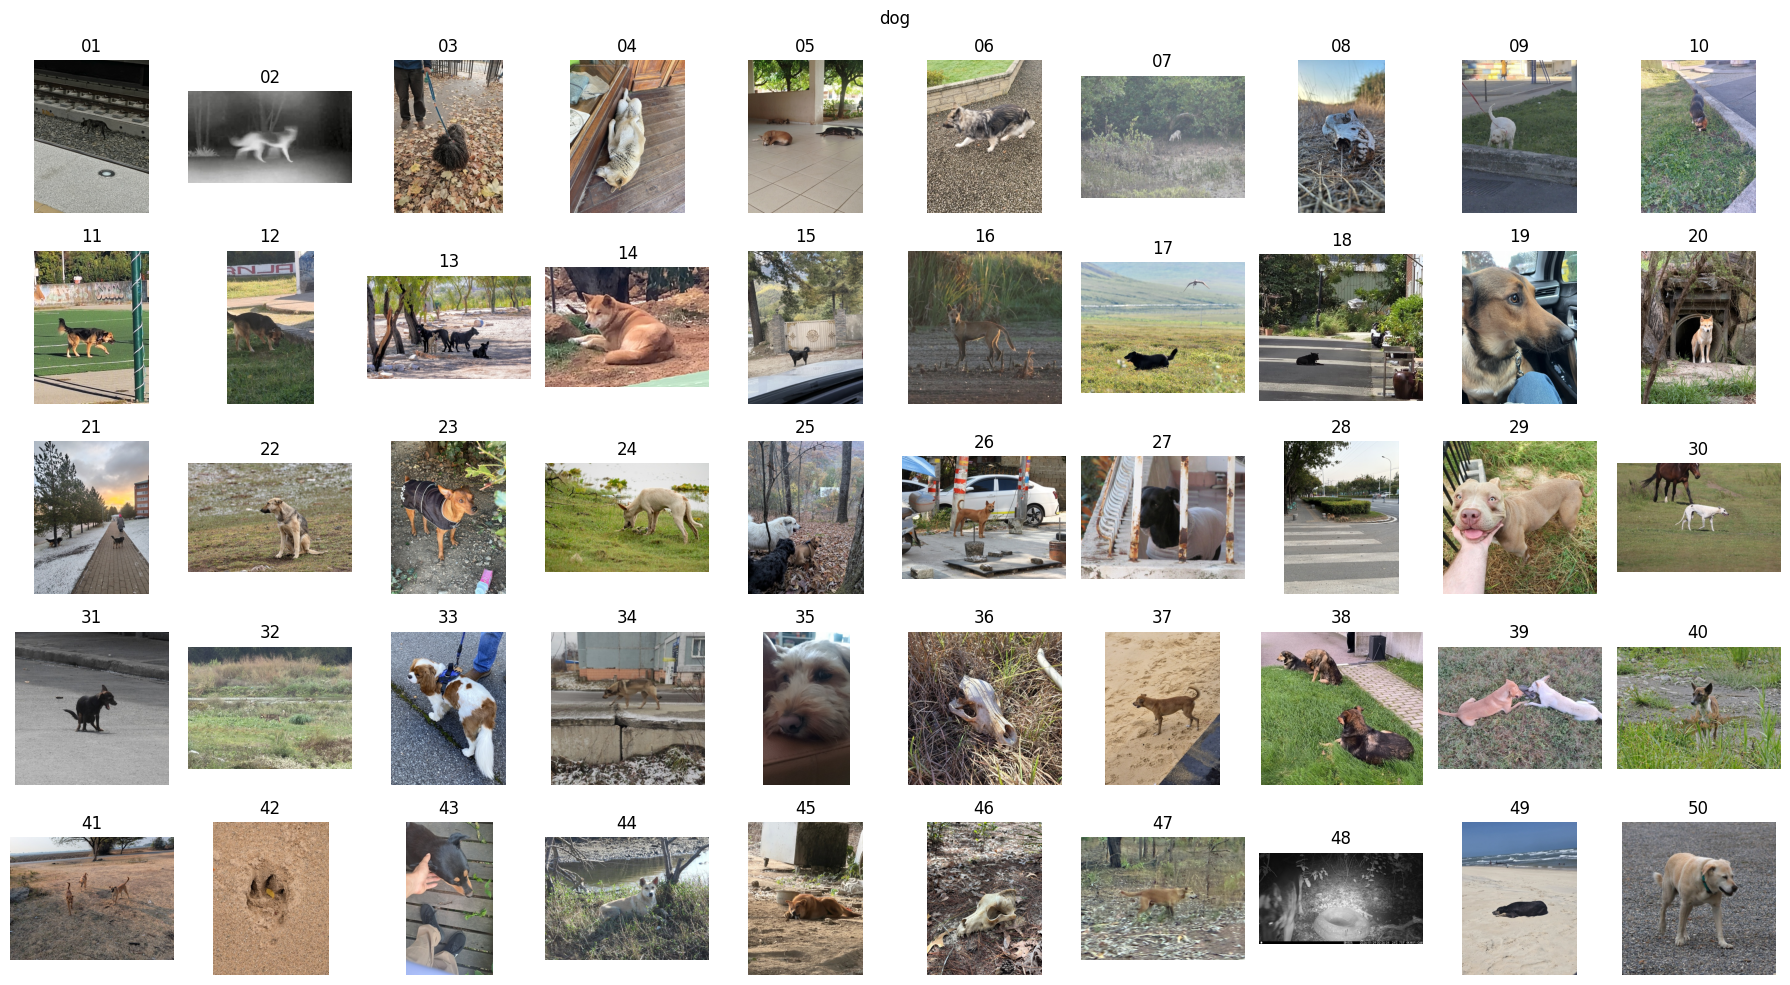

In [3]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from PIL import Image, ImageOps

ROOT = Path("/content/lab3_test_candidates")
TAXA = {"cat": 118552, "dog": 47144}
PER_CLASS = 50
LICENSES = ("cc0", "cc-by", "cc-by-sa")
API = "https://api.inaturalist.org/v1/observations"


def collect_photos(session, label, taxon_id, used_photos):
    (ROOT / label).mkdir(parents=True, exist_ok=True)
    selected = []
    used_observers = set()
    params = {
        "taxon_id": taxon_id,
        "photos": "true",
        "d1": "2023-01-01",
        "photo_license": ",".join(LICENSES),
        "per_page": 100,
        "order_by": "id",
        "order": "desc",
    }

    for _ in range(10):
        response = session.get(API, params=params, timeout=30)
        response.raise_for_status()
        observations = response.json()["results"]
        if not observations:
            break
        params["id_below"] = observations[-1]["id"]

        for obs in observations:
            observer = obs["user"]["id"]
            if observer in used_observers:
                continue

            photo = next(
                (p for p in obs["photos"] if p.get("url")
                 and p.get("license_code") in LICENSES and p["id"] not in used_photos),
                None,
            )
            if photo is None:
                continue

            image_url = photo["url"].replace("/square.", "/medium.")
            response = session.get(image_url, timeout=25)
            if response.status_code in (403, 404):
                continue
            response.raise_for_status()
            try:
                with Image.open(BytesIO(response.content)) as source:
                    image = ImageOps.exif_transpose(source).convert("RGB")
            except OSError:
                continue

            path = Path(label) / f"{len(selected) + 1:02d}.jpg"
            image.save(ROOT / path, quality=95)
            used_observers.add(observer)
            used_photos.add(photo["id"])
            selected.append({
                "file": path.as_posix(),
                "candidate_label": label,
                "observed_on": obs["observed_on"],
                "source": f"https://www.inaturalist.org/photos/{photo['id']}",
                "attribution": photo.get("attribution", ""),
                "license": photo["license_code"],
            })

            if len(selected) == PER_CLASS:
                return selected

    raise RuntimeError(f"{label}: собрано {len(selected)} из {PER_CLASS} фото.")


rows = []
used_photos = set()
with requests.Session() as session:
    for label, taxon_id in TAXA.items():
        print(f"Скачиваем {label}...", flush=True)
        rows.extend(collect_photos(session, label, taxon_id, used_photos))

manifest = pd.DataFrame(rows)
manifest.to_csv(ROOT / "sources.csv", index=False)
print(manifest["candidate_label"].value_counts().to_string())

for label in TAXA:
    files = manifest.loc[manifest["candidate_label"] == label, "file"]
    fig, axes = plt.subplots(5, 10, figsize=(18, 10))
    fig.suptitle(label)
    for ax, file in zip(axes.flat, files):
        with Image.open(ROOT / file) as image:
            ax.imshow(image)
        ax.set_title(Path(file).stem)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [4]:
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.models import ResNet18_Weights


DATA_ROOT = Path("/content/lab3_data")
CLASS_NAMES = {0: "cat", 1: "dog"}
BATCH_SIZE = 32


def load_oxford_metadata(root):
    OxfordIIITPet(root=root, split="trainval", download=True)

    pet_dir = root / "oxford-iiit-pet"
    annotations = pet_dir / "annotations" / "trainval.txt"
    records = []
    unreadable = []

    for line in annotations.read_text(encoding="utf-8").splitlines():
        image_id, _, species_id, _ = line.split()
        image_path = pet_dir / "images" / f"{image_id}.jpg"

        try:
            with Image.open(image_path) as image:
                image.load()
        except OSError:
            unreadable.append(image_path.name)
            continue

        label = int(species_id) - 1
        records.append({
            "path": str(image_path),
            "label": label,
            "class_name": CLASS_NAMES[label],
        })

    return pd.DataFrame(records), unreadable


class PetDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.samples = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        row = self.samples.iloc[index]
        with Image.open(row["path"]) as source:
            image = source.convert("RGB")
        return self.transform(image), int(row["label"])


def make_loader(dataframe, transform, *, shuffle, device):
    return DataLoader(
        PetDataset(dataframe, transform),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
    )


def check_batch(loader, device):
    images, labels = next(iter(loader))
    images = images.to(device)

    device_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"
    print("Устройство:", device_name)
    print("Форма батча:", tuple(images.shape))
    print("Форма меток:", tuple(labels.shape))
    print("Первые 8 меток:", labels[:8].tolist())


pets_df, unreadable = load_oxford_metadata(DATA_ROOT)
train_df, val_df = train_test_split(
    pets_df,
    test_size=0.20,
    random_state=42,
    stratify=pets_df["label"],
)

counts = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val": val_df["class_name"].value_counts(),
}).reindex(["cat", "dog"])

print(counts.to_string())
print("Пропущено нечитаемых фото:", len(unreadable))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ResNet18_Weights.DEFAULT
val_transform = weights.transforms()
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    val_transform,
])

train_loader = make_loader(train_df, train_transform, shuffle=True, device=device)
val_loader = make_loader(val_df, val_transform, shuffle=False, device=device)
check_batch(train_loader, device)

100%|██████████| 792M/792M [00:07<00:00, 112MB/s] 
100%|██████████| 19.2M/19.2M [00:00<00:00, 103MB/s] 


            train  val
class_name            
cat           950  238
dog          1994  498
Пропущено нечитаемых фото: 0
Устройство: Tesla T4
Форма батча: (32, 3, 224, 224)
Форма меток: (32,)
Первые 8 меток: [1, 1, 1, 1, 1, 1, 1, 1]


In [5]:
import torch
from torch import nn
from torch.optim import AdamW
from torchvision.models import resnet18

LEARNING_RATE = 1e-4

model = resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

model.eval()
images, labels = next(iter(val_loader))
images = images.to(device)
labels = labels.to(device)

with torch.inference_mode():
    logits = model(images)
    loss = criterion(logits, labels)

print("Последний слой:", model.fc)
print("Форма выхода:", tuple(logits.shape))
print(f"Loss на первом батче: {loss.item():.4f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s]


Последний слой: Linear(in_features=512, out_features=2, bias=True)
Форма выхода: (32, 2)
Loss на первом батче: 0.6660


In [6]:
from pathlib import Path

import pandas as pd
import torch


EPOCHS = 5
CHECKPOINT = Path("/content/resnet18_best.pth")


def run_epoch(model, loader, criterion, device, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_images += batch_size

    return total_loss / total_images, total_correct / total_images


history = []
best_score = (-1.0, float("-inf"))

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, device, optimizer
    )
    val_loss, val_acc = run_epoch(model, val_loader, criterion, device)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
    })

    score = (val_acc, -val_loss)
    if score > best_score:
        best_score = score
        best_epoch = epoch
        torch.save(model.state_dict(), CHECKPOINT)

    print(
        f"Эпоха {epoch}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_acc:.2%} | "
        f"val loss {val_loss:.4f}, accuracy {val_acc:.2%}",
        flush=True,
    )

history_df = pd.DataFrame(history)
history_df.to_csv("/content/training_history.csv", index=False)

model.load_state_dict(torch.load(CHECKPOINT, map_location=device, weights_only=True))
print(f"\nЛучшая эпоха: {best_epoch}, val accuracy: {best_score[0]:.2%}")

Эпоха 1/5 | train loss 0.0760, accuracy 97.28% | val loss 0.0532, accuracy 97.69%
Эпоха 2/5 | train loss 0.0127, accuracy 99.69% | val loss 0.0187, accuracy 99.05%
Эпоха 3/5 | train loss 0.0073, accuracy 99.76% | val loss 0.0129, accuracy 99.46%
Эпоха 4/5 | train loss 0.0069, accuracy 99.80% | val loss 0.0298, accuracy 98.78%
Эпоха 5/5 | train loss 0.0054, accuracy 99.83% | val loss 0.0160, accuracy 99.32%

Лучшая эпоха: 3, val accuracy: 99.46%


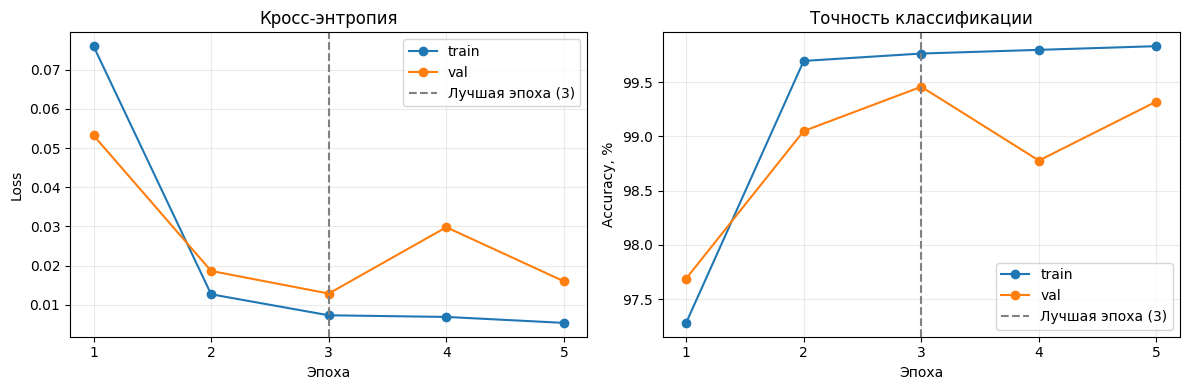

In [7]:
import matplotlib.pyplot as plt

epochs = history_df["epoch"]
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs, history_df["train_loss"], "o-", label="train")
ax_loss.plot(epochs, history_df["val_loss"], "o-", label="val")
ax_loss.set_title("Кросс-энтропия")
ax_loss.set_ylabel("Loss")

ax_acc.plot(epochs, history_df["train_acc"] * 100, "o-", label="train")
ax_acc.plot(epochs, history_df["val_acc"] * 100, "o-", label="val")
ax_acc.set_title("Точность классификации")
ax_acc.set_ylabel("Accuracy, %")

for ax in (ax_loss, ax_acc):
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label=f"Лучшая эпоха ({best_epoch})",
    )
    ax.set_xlabel("Эпоха")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
fig.savefig("/content/training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

Test accuracy: 78.00% (78/100)


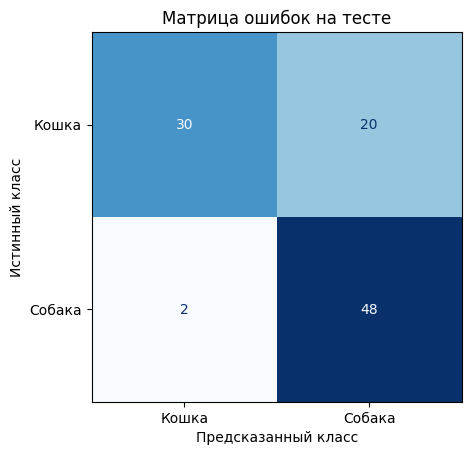

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay

TEST_ROOT = Path("/content/lab3_test_candidates")
OUTPUT_DIR = Path("/content")


@torch.inference_mode()
def predict_classes(model, loader, device):
    model.eval()
    predictions = []

    for images, _ in loader:
        logits = model(images.to(device))
        predictions.extend(logits.argmax(dim=1).cpu().tolist())

    return predictions


test_df = pd.read_csv(TEST_ROOT / "sources.csv")
class_to_label = {name: label for label, name in CLASS_NAMES.items()}

counts = test_df["candidate_label"].value_counts().to_dict()
if counts != {"cat": 50, "dog": 50} or test_df["file"].duplicated().any():
    raise ValueError("Для теста нужны 50 фото кошек и 50 фото собак с уникальными путями.")

test_df["path"] = test_df["file"].map(lambda file: str(TEST_ROOT / file))
test_df["label"] = test_df["candidate_label"].map(class_to_label)

test_loader = make_loader(test_df, val_transform, shuffle=False, device=device)
model.load_state_dict(torch.load(CHECKPOINT, map_location=device, weights_only=True))

test_df["predicted_label"] = predict_classes(model, test_loader, device)
test_df["predicted_class"] = test_df["predicted_label"].map(CLASS_NAMES)
test_df["correct"] = test_df["predicted_label"] == test_df["label"]

correct = int(test_df["correct"].sum())
print(f"Test accuracy: {correct / len(test_df):.2%} ({correct}/{len(test_df)})")
test_df.drop(columns="path").to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

display = ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_df["predicted_label"],
    labels=[0, 1],
    display_labels=["Кошка", "Собака"],
    cmap="Blues",
    colorbar=False,
)

display.ax_.set(
    title="Матрица ошибок на тесте",
    xlabel="Предсказанный класс",
    ylabel="Истинный класс",
)

display.figure_.savefig(
    OUTPUT_DIR / "test_confusion_matrix.png", dpi=180, bbox_inches="tight"
)

plt.show()